# Workout Form Classifier (Push-up & Squat)

**Pipeline:** video → MediaPipe body keypoints → joint angles / ratios → Random Forest → good / bad form

| # | Section | What you do there |
|---|---------|-------------------|
| 1 | Setup & config | Paths and settings (edit this first) |
| 2 | Feature functions | Turn keypoints into angles (writes `features.py`) |
| 3 | Skeleton sanity check | Look at the skeleton on a few videos |
| 4 | Feature extraction | Slow step. Videos → CSV. Cached after the first run |
| 4b | Extra push-up clips | Your additional good/bad push-up videos |
| 5 | EDA | Data quality and which features separate good from bad |
| 6 | Training & evaluation | Leave-one-subject-out validation |
| 6b | Other models | Video-level models and sliding-window model |
| 7 | Cross-dataset tests | Train on one source, test on the other, list the wrong clips |
| 8 | Squat jump-filter experiment | Does the tracking-jump filter hurt squat? |
| 9 | Final models | Train on everything and save for the app |
| 10 | Predict one video | Try a saved model on a single video |

**Run order:** top to bottom. Live webcam demo is in `live_demo.py`.

## 1. Setup & config

Edit the paths here. `CONFIG` says which folder and camera view to use for each exercise:
push-up from the **side**, squat from the **front**. Diagonal is ignored because angles get distorted.

Extraction (section 4) is the slow part, so its results are cached in `outputs/`. Set `FORCE_EXTRACT = True` to redo it.

In [1]:
import re, warnings
from pathlib import Path
from collections import Counter

import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import mannwhitneyu
from tqdm.auto import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

# ---- paths ----
DATASET_ROOT = Path("dataset_exercise_quality")  # contains push_up/ and squat/ (each: good|bad / front|side|diagonal)
EXTRA_ROOT = Path("dataset_exercise_quality/data_extra")  # extra push-up clips: <EXTRA_ROOT>/pushup/good|bad/[person_folder/]*.mp4
OUT_DIR = Path("outputs")                        # CSVs, models (git-ignored)
OUT_DIR.mkdir(exist_ok=True)

# ---- exercise -> (dataset folder, camera view) ----
CONFIG = {"pushup": ("push_up", "side"), "squat": ("squat", "front")}

# ---- extraction settings ----
EVERY_N = 3          # use every Nth frame (neighbouring frames are near-duplicates)
# tracking-jump filter: drops frames where the skeleton "teleports" (probably tracking the wrong person).
# Squats move a lot, so this may delete real frames; section 8 tests that.
USE_JUMP_FILTER = {"pushup": True, "squat": True}
MAX_JUMP = {"pushup": 0.15, "squat": 0.15}   # max body-centre movement between sampled frames (normalised coords)
MIN_FRAMES = 15      # videos with fewer usable frames are dropped
FORCE_EXTRACT = False

# dataset layout: DATASET_ROOT/<exercise>/<good|bad>/<view>/<video>.mp4
# the subject id is read from the filename (first number, e.g. subject_005_... -> 5)

## 2. Feature functions

Raw keypoint coordinates change with camera distance and where the person stands. **Angles and ratios don't**, so the model learns *form* instead of *position*.

**Push-up (side view)**
- `elbow_angle`: how deep the push-up is
- `body_line`: shoulder-hip-ankle angle. ~180° = straight plank, lower = hips sagging or piking
- `hip_angle`, `knee_angle`: bent knees or folded hips = cheating

Only one side of the body is really visible in side view, so we use whichever side faces the camera. Facing left or right doesn't matter, because angles are identical when mirrored.

**Squat (front view)**
- `knee_angle_l/r`: how far down
- `knee_ankle_ratio`: knee width / ankle width. Below 1 means knees caving in
- `hip_ankle_ratio`: stance width vs hip width
- `hip_depth`: (knee height - hip height) / torso length. ~0 at parallel, positive = hips still above knees (front view can't see depth directly, so this is a proxy)
- `shoulder_tilt`, `hip_tilt`: leaning sideways

The next cell **writes `features.py`** (so `live_demo.py` can import the same code) and then imports it.

In [2]:
%%writefile features.py
import numpy as np
import mediapipe as mp

mp_pose = mp.solutions.pose
L = mp_pose.PoseLandmark
MIN_VIS = 0.5   # landmarks below this visibility are treated as unreliable


def angle(a, b, c):
    """angle at point b formed by a-b-c, in degrees"""
    a, b, c = np.array(a), np.array(b), np.array(c)
    ba, bc = a - b, c - b
    cos = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-6)
    return float(np.degrees(np.arccos(np.clip(cos, -1, 1))))


def pt(lm, idx, w, h):
    return (lm[idx].x * w, lm[idx].y * h)   # scale by w,h so angles aren't distorted


def pick_side(lm):
    """which side of the body faces the camera (higher visibility)"""
    def vis(s):
        return np.mean([lm[getattr(L, f"{s}_{n}")].visibility
                        for n in ("SHOULDER", "HIP", "ANKLE")])
    return "LEFT" if vis("LEFT") >= vis("RIGHT") else "RIGHT"


def track_stats(lm):
    """body centre + torso size (normalised coords), used to detect tracking jumps"""
    sx = (lm[L.LEFT_SHOULDER].x + lm[L.RIGHT_SHOULDER].x) / 2
    sy = (lm[L.LEFT_SHOULDER].y + lm[L.RIGHT_SHOULDER].y) / 2
    hx = (lm[L.LEFT_HIP].x + lm[L.RIGHT_HIP].x) / 2
    hy = (lm[L.LEFT_HIP].y + lm[L.RIGHT_HIP].y) / 2
    return (sx + hx) / 2, (sy + hy) / 2, float(np.hypot(sx - hx, sy - hy))


def pushup_features(lm, w, h, side):
    names = ("SHOULDER", "ELBOW", "WRIST", "HIP", "KNEE", "ANKLE")
    if min(lm[getattr(L, f"{side}_{n}")].visibility for n in names) < MIN_VIS:
        return None
    g = lambda n: pt(lm, getattr(L, f"{side}_{n}"), w, h)
    sh, el, wr = g("SHOULDER"), g("ELBOW"), g("WRIST")
    hip, kn, an = g("HIP"), g("KNEE"), g("ANKLE")
    return {
        "elbow_angle": angle(sh, el, wr),
        "body_line": angle(sh, hip, an),   # ~180 = straight, low = sagging/piking
        "hip_angle": angle(sh, hip, kn),
        "knee_angle": angle(hip, kn, an),  # bent knees = cheating
    }


def squat_features(lm, w, h, side=None):
    names = ("LEFT_SHOULDER", "RIGHT_SHOULDER", "LEFT_HIP", "RIGHT_HIP",
             "LEFT_KNEE", "RIGHT_KNEE", "LEFT_ANKLE", "RIGHT_ANKLE")
    if min(lm[getattr(L, n)].visibility for n in names) < MIN_VIS:
        return None
    g = lambda n: pt(lm, getattr(L, n), w, h)
    lsh, rsh = g("LEFT_SHOULDER"), g("RIGHT_SHOULDER")
    lh, rh = g("LEFT_HIP"), g("RIGHT_HIP")
    lk, rk = g("LEFT_KNEE"), g("RIGHT_KNEE")
    la, ra = g("LEFT_ANKLE"), g("RIGHT_ANKLE")

    torso = np.hypot((lsh[0] + rsh[0] - lh[0] - rh[0]) / 2,
                     (lsh[1] + rsh[1] - lh[1] - rh[1]) / 2) + 1e-6
    ankle_w = max(abs(la[0] - ra[0]), 0.02 * w)   # guard against feet-together blow-up
    knee_y, hip_y = (lk[1] + rk[1]) / 2, (lh[1] + rh[1]) / 2
    return {
        "knee_angle_l": angle(lh, lk, la),
        "knee_angle_r": angle(rh, rk, ra),
        "knee_ankle_ratio": abs(lk[0] - rk[0]) / ankle_w,   # <1 = knees caving in
        "hip_ankle_ratio": abs(lh[0] - rh[0]) / ankle_w,
        "hip_depth": (knee_y - hip_y) / torso,              # ~0 at parallel, >0 = hips above knees
        "shoulder_tilt": abs(lsh[1] - rsh[1]) / torso,      # leaning sideways
        "hip_tilt": abs(lh[1] - rh[1]) / torso,
    }


EXTRACTORS = {"pushup": pushup_features, "squat": squat_features}

Overwriting features.py


In [3]:
import importlib, features
importlib.reload(features)
from features import mp_pose, pick_side, track_stats, EXTRACTORS
print("features loaded:", list(EXTRACTORS))

features loaded: ['pushup', 'squat']


## 3. Skeleton sanity check

MediaPipe Pose tracks **one person**. With people in the background it can occasionally lock onto the wrong one. This draws the skeleton on the middle frame of a few videos so you can eyeball it.

If the skeleton is on the exerciser in nearly all of them, you're fine. Increase `n` to check more videos.

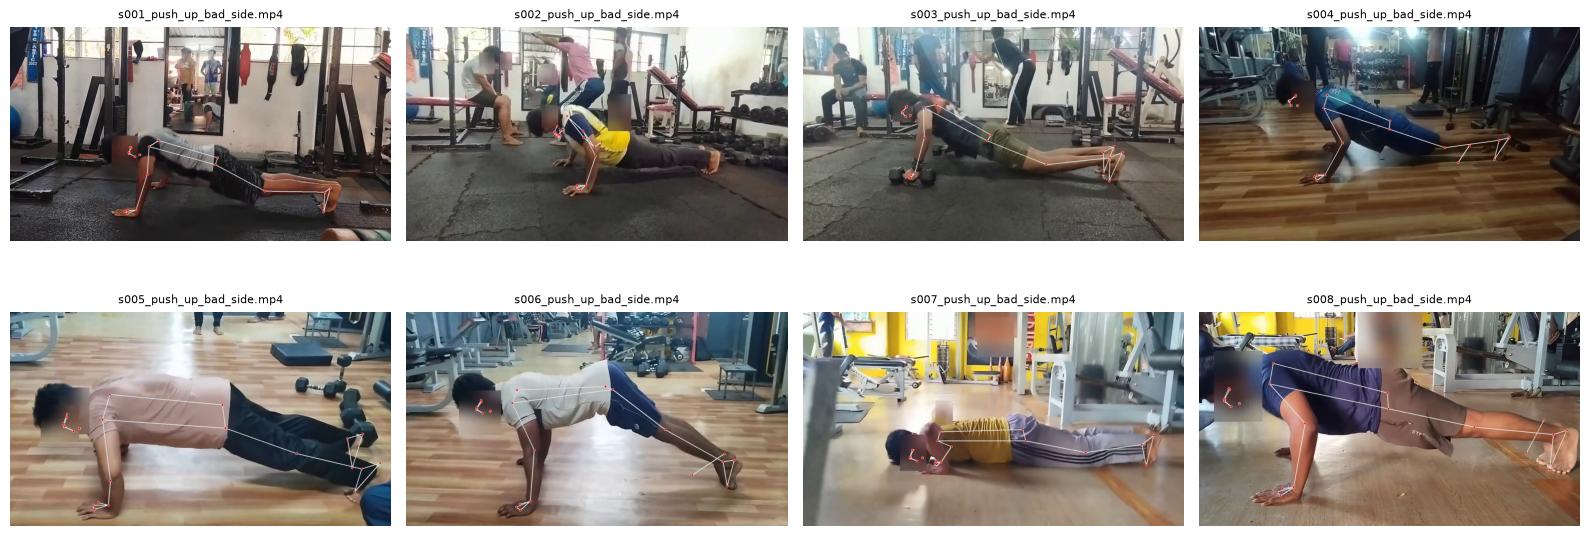

In [4]:
import mediapipe as mp
draw_utils = mp.solutions.drawing_utils


def show_skeletons(exercise, n=8, cols=4):
    folder, view = CONFIG[exercise]
    paths = sorted((DATASET_ROOT / folder).glob(f"*/{view}/*.mp4"))[:n]
    if not paths:
        print(f"no videos found under {DATASET_ROOT}/{folder}")
        return
    rows = int(np.ceil(len(paths) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, path in zip(axes, paths):
        cap = cv2.VideoCapture(str(path))
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT) // 2))
        ok, frame = cap.read()
        cap.release()
        if not ok:
            continue
        with mp_pose.Pose(static_image_mode=True) as pose:
            res = pose.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        if res.pose_landmarks:
            draw_utils.draw_landmarks(frame, res.pose_landmarks, mp_pose.POSE_CONNECTIONS)
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        ax.set_title(path.name.replace("subject_", "s"), fontsize=8)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


show_skeletons("pushup")

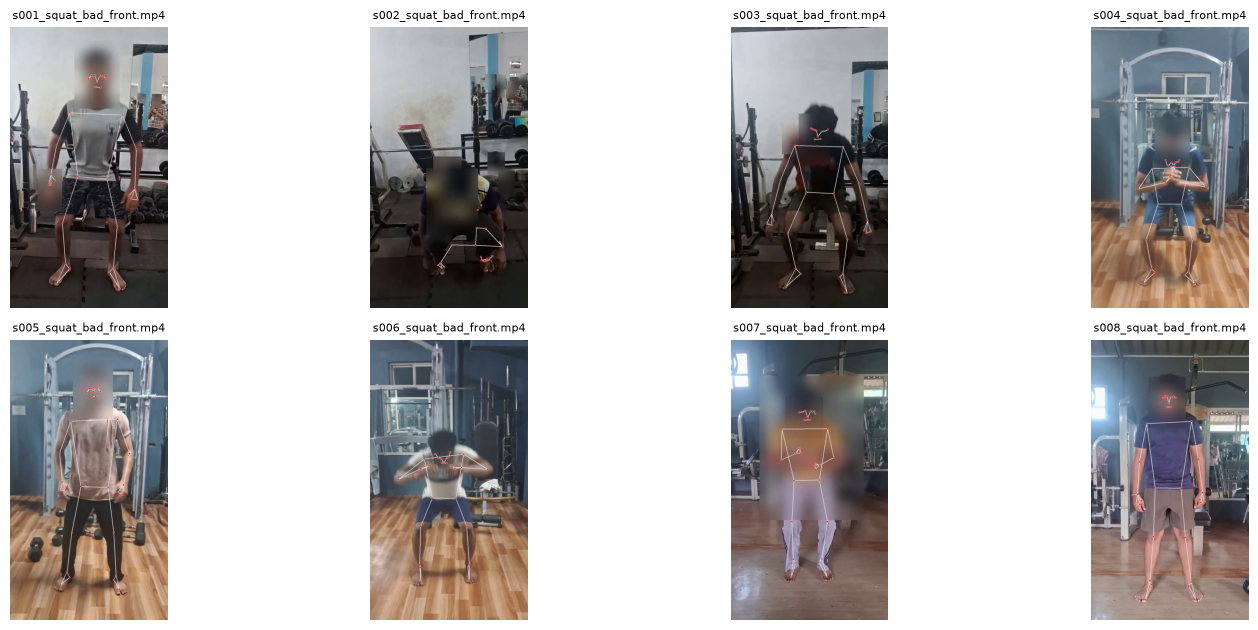

In [5]:
show_skeletons("squat")

## 4. Feature extraction

For each video: run MediaPipe on every `EVERY_N`-th frame and turn the keypoints into feature rows.

Quality controls built in:
- **Side is locked per video** (push-up): majority vote of the first 30 frames, so it can't flip-flop mid-video.
- **Visibility filter**: frames where a needed landmark is below `MIN_VIS` visibility are skipped.
- **Jump filter**: if the body centre teleports or the torso suddenly changes size, MediaPipe probably switched to a background person, so those frames are dropped. If the change persists for 10 sampled frames it's treated as real and re-anchored.
- **Too few frames**: videos with fewer than `MIN_FRAMES` usable frames are dropped.

A QC table is kept per video (`sampled`, `no_pose`, `low_vis`, `jumps`, `kept`). Section 5 uses it.

In [6]:
def lock_side(path, n_frames=30):
    """majority vote over the first detected frames -> one side per video"""
    votes = []
    cap = cv2.VideoCapture(str(path))
    with mp_pose.Pose(min_detection_confidence=0.5) as pose:
        while cap.isOpened() and len(votes) < n_frames:
            ok, frame = cap.read()
            if not ok:
                break
            res = pose.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            if res.pose_landmarks:
                votes.append(pick_side(res.pose_landmarks.landmark))
    cap.release()
    return Counter(votes).most_common(1)[0][0] if votes else "LEFT"


def extract_video(path, exercise, jump_filter=None, max_jump=None):
    """one video -> (list of feature dicts, QC stats)"""
    jump_filter = USE_JUMP_FILTER[exercise] if jump_filter is None else jump_filter
    max_jump = MAX_JUMP[exercise] if max_jump is None else max_jump
    extract = EXTRACTORS[exercise]
    side = lock_side(path) if exercise == "pushup" else None
    rows, prev, streak, i = [], None, 0, 0
    st = dict(sampled=0, no_pose=0, low_vis=0, jumps=0)

    cap = cv2.VideoCapture(str(path))
    with mp_pose.Pose(min_detection_confidence=0.5) as pose:
        while cap.isOpened():
            ok, frame = cap.read()
            if not ok:
                break
            i += 1
            if i % EVERY_N:
                continue
            st["sampled"] += 1
            h, w = frame.shape[:2]
            res = pose.process(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            if not res.pose_landmarks:
                st["no_pose"] += 1
                continue
            lm = res.pose_landmarks.landmark

            # tracking-jump filter
            cur = track_stats(lm)
            if prev is not None:
                jump = np.hypot(cur[0] - prev[0], cur[1] - prev[1])
                ratio = cur[2] / (prev[2] + 1e-6)
                if jump_filter and (jump > max_jump or not (0.6 < ratio < 1.6)):
                    st["jumps"] += 1
                    streak += 1
                    if streak >= 10:          # persistent change = real, re-anchor
                        prev, streak = None, 0
                    continue
            prev, streak = cur, 0

            feats = extract(lm, w, h, side)
            if feats is None:
                st["low_vis"] += 1
                continue
            feats["frame"] = i
            rows.append(feats)
    cap.release()
    st["kept"], st["side"] = len(rows), side or ""
    return rows, st

In [7]:
def collect_items(exercise):
    """list of (video path, label, subject) for the downloaded dataset. label: 1 = good, 0 = bad"""
    folder, view = CONFIG[exercise]
    items = []
    for p in sorted((DATASET_ROOT / folder).glob(f"*/{view}/*.mp4")):
        quality = p.parent.parent.name.lower()            # "good" or "bad"
        if quality not in ("good", "bad"):
            continue
        m = re.search(r"subject_?(\d+)", p.name, re.I) or re.search(r"(\d+)", p.name)
        items.append((p, int(quality == "good"), int(m.group(1)) if m else -1))
    return items


def build_dataset(exercise, **kw):
    """features for every dataset video. kw goes to extract_video (e.g. jump_filter=False)"""
    items = collect_items(exercise)
    if not items:
        print(f"!! no videos found for {exercise}. Check DATASET_ROOT / folder layout.")
    rows_all, qc = [], []
    for path, label, subject in tqdm(items, desc=exercise):
        rows, st = extract_video(path, exercise, **kw)
        qc.append(dict(video=path.name, label=label, subject=subject, **st))
        if st["kept"] < MIN_FRAMES:
            continue
        for r in rows:
            r.update(label=label, video=path.name, subject=subject, side=st["side"])
        rows_all += rows
    return pd.DataFrame(rows_all), pd.DataFrame(qc)

In [8]:
DATA, QC = {}, {}
for ex in CONFIG:
    f_csv, q_csv = OUT_DIR / f"{ex}_features.csv", OUT_DIR / f"{ex}_qc.csv"
    if f_csv.exists() and q_csv.exists() and not FORCE_EXTRACT:
        DATA[ex], QC[ex] = pd.read_csv(f_csv), pd.read_csv(q_csv)
        print(f"[{ex}] loaded cached CSVs")
    else:
        DATA[ex], QC[ex] = build_dataset(ex)
        DATA[ex].to_csv(f_csv, index=False)
        QC[ex].to_csv(q_csv, index=False)
    d = DATA[ex]
    assert len(d) > 0, f"no data for {ex}; check DATASET_ROOT and folder layout"
    assert d.subject.nunique() > 1, f"couldn't read subject ids from the {ex} filenames; leave-one-subject-out needs them"
    print(f"[{ex}] {d.shape} | {d.video.nunique()} videos | {d.subject.nunique()} subjects | "
          f"videos per label: {d.groupby('label').video.nunique().to_dict()}")

[pushup] loaded cached CSVs
[pushup] (4850, 9) | 48 videos | 24 subjects | videos per label: {0: 24, 1: 24}
[squat] loaded cached CSVs
[squat] (6281, 12) | 50 videos | 25 subjects | videos per label: {0: 25, 1: 25}


## 4b. Extra push-up clips

Additional good/bad push-up videos from another source. They are kept **separate** from the main dataset (named `x_...`, subject ids start at 1000) so section 7 can use them as an independent test.

Folder layout under `EXTRA_ROOT`: `pushup/good/` and `pushup/bad/`. Optional person subfolders (`p01/`, `p02/`...) group clips of the same person under one subject id. Without subfolders, every clip counts as its own person.

If `EXTRA_ROOT/pushup` doesn't exist, this section is skipped and `EXTRA = None`.

In [9]:
VIDEO_EXT = {".mp4", ".mov", ".avi", ".mkv"}


def collect_extra(exercise):
    out, persons = [], {}
    for q, label in (("good", 1), ("bad", 0)):
        base = EXTRA_ROOT / exercise / q
        for p in sorted(base.rglob("*")):
            if p.suffix.lower() not in VIDEO_EXT:
                continue
            key = p.parent.name.lower() if p.parent != base else p.stem
            subject = persons.setdefault(key, 1000 + len(persons))
            out.append((p, label, subject))
    return out


def build_extra(exercise, **kw):
    rows_all = []
    for path, label, subject in tqdm(collect_extra(exercise), desc=f"{exercise} (extra)"):
        rows, st = extract_video(path, exercise, **kw)
        if st["kept"] < MIN_FRAMES:
            print("dropped (too few frames):", path.name, st)
            continue
        for r in rows:
            r.update(label=label, video=f"x_{path.name}", subject=subject, side=st["side"])
        rows_all += rows
    return pd.DataFrame(rows_all)


EXTRA = None
if (EXTRA_ROOT / "pushup").exists():
    found = collect_extra("pushup")
    print(f"found {len(found)} extra videos | good: {sum(l for _, l, _ in found)} | bad: {sum(1 - l for _, l, _ in found)}")
    f = OUT_DIR / "pushup_extra.csv"
    if f.exists() and not FORCE_EXTRACT:
        EXTRA = pd.read_csv(f)
    else:
        EXTRA = build_extra("pushup")
        if len(EXTRA):
            EXTRA.to_csv(f, index=False)
    print(EXTRA.shape, "| videos:", EXTRA.video.nunique(),
          "| per label:", EXTRA.groupby("label").video.nunique().to_dict())
else:
    print(f"{EXTRA_ROOT / 'pushup'} not found, skipping extra clips")

found 100 extra videos | good: 50 | bad: 50
(3568, 9) | videos: 99 | per label: {0: 49, 1: 50}


## 5. EDA

Change `EDA_EXERCISE` below and re-run this section to look at the other exercise.

What to look for in each part:
- **Overview**: about 26 videos per label, similar frame counts for good and bad.
- **Tracking quality**: few flagged videos. Many flagged means MediaPipe struggles with this data and no model will fix that.
- **Distributions**: features where red and green barely overlap are strong. Full overlap means the feature is useless alone.
- **Separation (AUC)**: tested on one number per video, because frames from the same video aren't independent. 0.5 = useless, near 0 or 1 = strong.
- **Correlation**: two features at 0.95+ carry the same signal.
- **Time series**: the angle should look like a wave, one cycle per rep. Noisy spikes mean bad tracking for that video.

In [10]:
EDA_EXERCISE = "pushup"   # <- change to "squat" and re-run this section

ex = EDA_EXERCISE
df, qc = DATA[ex], QC[ex].copy()
META = ["label", "video", "subject", "side", "frame"]
feats = [c for c in df.columns if c not in META]
COL = {0: "tab:red", 1: "tab:green"}
NAME = {0: "bad", 1: "good"}
vids = df.groupby("video").agg(label=("label", "first"), frames=("frame", "size"))

### 5.1 Overview

In [11]:
print(f"rows: {len(df)} | videos: {df.video.nunique()} | subjects: {df.subject.nunique()}")
print("videos per label:", vids.label.map(NAME).value_counts().to_dict())
print("frames per label:", df.label.map(NAME).value_counts().to_dict())
print("\nframes per video, by label:")
display(vids.groupby("label").frames.describe().round(1).rename(index=NAME))
if ex == "pushup":
    print("side chosen per video:", df.groupby("video").side.first().value_counts().to_dict())

rows: 4850 | videos: 48 | subjects: 24
videos per label: {'bad': 24, 'good': 24}
frames per label: {'good': 2504, 'bad': 2346}

frames per video, by label:


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
bad,24.0,97.8,32.3,32.0,78.5,87.5,122.2,158.0
good,24.0,104.3,36.2,32.0,86.8,100.0,131.0,156.0


side chosen per video: {'LEFT': 48}


### 5.2 Tracking quality

videos with >30% frames lost or <30 frames kept: 0
mean frames lost: good=0.03  bad=0.02


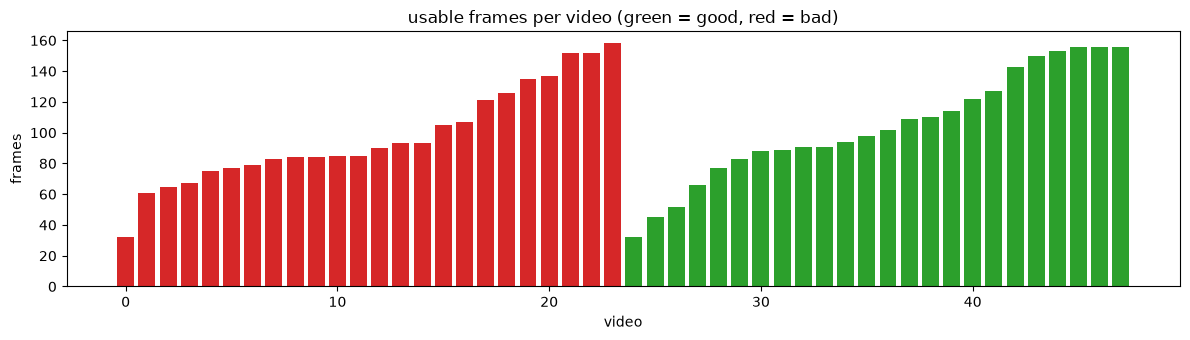

In [12]:
qc["lost"] = 1 - qc["kept"] / qc["sampled"].clip(lower=1)
flagged = qc[(qc["lost"] > 0.3) | (qc["kept"] < 30)]
print(f"videos with >30% frames lost or <30 frames kept: {len(flagged)}")
if len(flagged):
    display(flagged[["video", "kept", "sampled", "no_pose", "low_vis", "jumps"]])
print(f"mean frames lost: good={qc[qc.label == 1].lost.mean():.2f}  bad={qc[qc.label == 0].lost.mean():.2f}")

v = vids.sort_values(["label", "frames"])
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(range(len(v)), v.frames, color=[COL[l] for l in v.label])
ax.set_title("usable frames per video (green = good, red = bad)")
ax.set_xlabel("video"); ax.set_ylabel("frames")
plt.tight_layout(); plt.show()

### 5.3 Feature distributions (good vs bad)

label,bad,good
elbow_angle,145.86,132.42
body_line,167.83,173.12
hip_angle,165.47,171.82
knee_angle,164.87,168.17


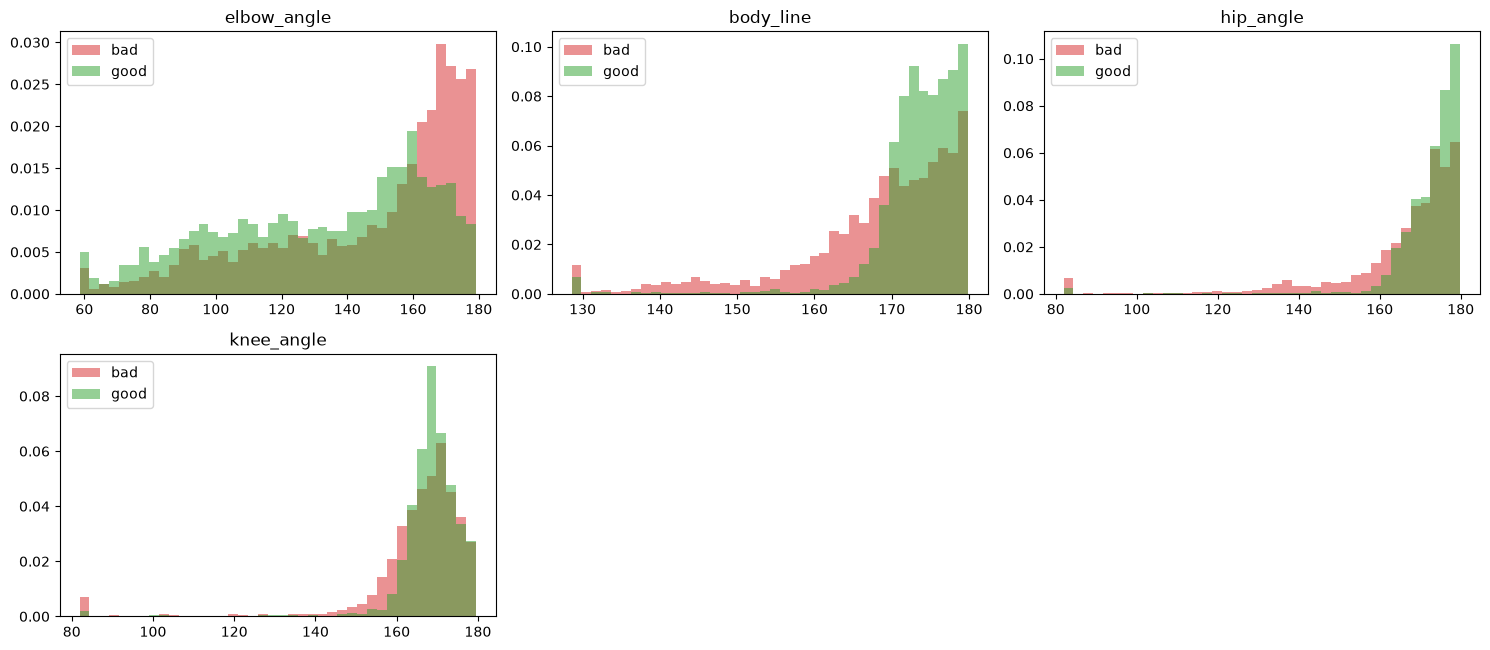

In [13]:
display(df.groupby("label")[feats].mean().round(2).rename(index=NAME).T)

ncols = 3
nrows = int(np.ceil(len(feats) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.3 * nrows))
axes = np.atleast_1d(axes).ravel()
for ax, f in zip(axes, feats):
    lo, hi = df[f].quantile([0.01, 0.99])
    for lab in (0, 1):
        ax.hist(df.loc[df.label == lab, f].clip(lo, hi), bins=40, alpha=0.5,
                color=COL[lab], density=True, label=NAME[lab])
    ax.set_title(f); ax.legend()
for ax in axes[len(feats):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### 5.4 Which features separate good from bad? (video level)

In [14]:
agg = df.groupby("video")[feats].agg(["mean", "std", "min", "max"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg["label"] = vids["label"]

res = []
for col in agg.columns[:-1]:
    g, b = agg.loc[agg.label == 1, col].dropna(), agg.loc[agg.label == 0, col].dropna()
    if len(g) < 3 or len(b) < 3:
        continue
    u, p = mannwhitneyu(g, b, alternative="two-sided")
    res.append((col, u / (len(g) * len(b)), p))   # AUC: 0.5 = no separation
res = pd.DataFrame(res, columns=["feature", "AUC", "p"])
res["strength"] = (res.AUC - 0.5).abs()
res = res.sort_values("strength", ascending=False)
print("Top features (AUC 0.5 = useless, near 0 or 1 = strong):")
display(res.head(12).round(3))

Top features (AUC 0.5 = useless, near 0 or 1 = strong):


,feature,AUC,p,strength
4,body_line_mean,0.734,0.006,0.234
0,elbow_angle_mean,0.277,0.008,0.223
8,hip_angle_mean,0.716,0.011,0.216
13,knee_angle_std,0.334,0.050,0.166
9,hip_angle_std,0.343,0.063,0.157
14,knee_angle_min,0.645,0.087,0.145
10,hip_angle_min,0.635,0.112,0.135
3,elbow_angle_max,0.376,0.143,0.124
5,body_line_std,0.383,0.167,0.117
7,body_line_max,0.609,0.201,0.109


### 5.5 Correlation between features

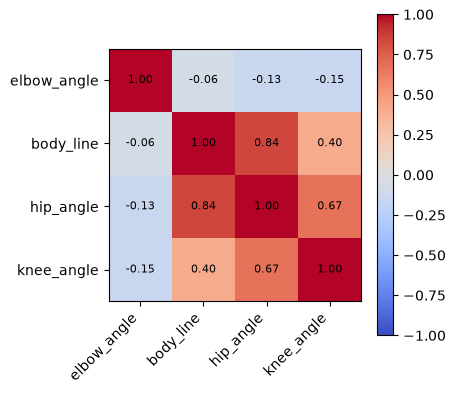

In [15]:
corr = df[feats].corr()
fig, ax = plt.subplots(figsize=(1 + 0.9 * len(feats), 1 + 0.8 * len(feats)))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feats))); ax.set_xticklabels(feats, rotation=45, ha="right")
ax.set_yticks(range(len(feats))); ax.set_yticklabels(feats)
for i in range(len(feats)):
    for j in range(len(feats)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()

### 5.6 Signal over time (should look like reps)

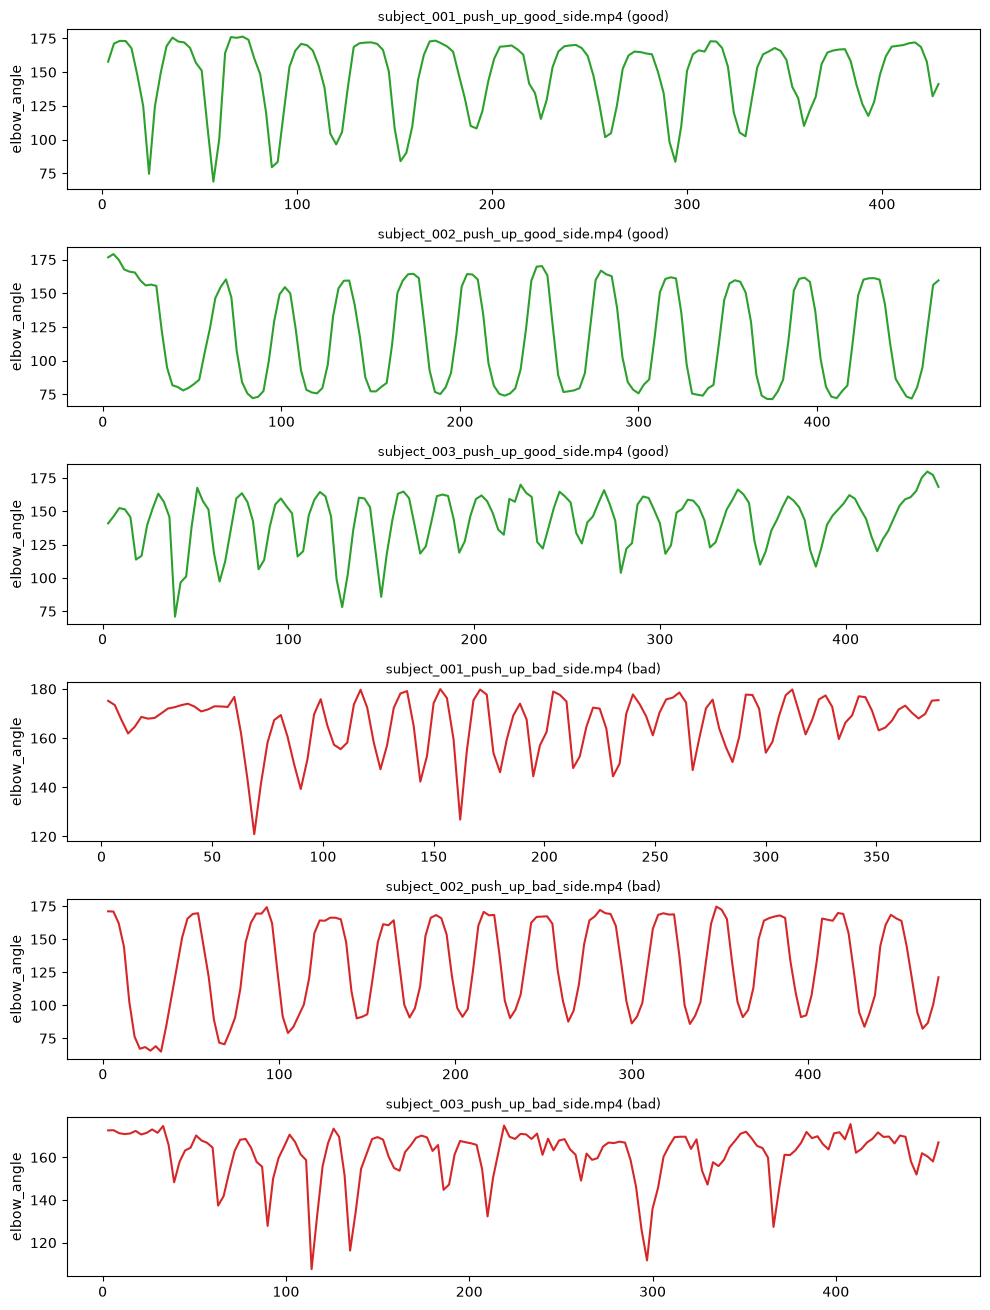

In [16]:
f0 = feats[0]
pick = list(vids[vids.label == 1].index[:3]) + list(vids[vids.label == 0].index[:3])
fig, axes = plt.subplots(len(pick), 1, figsize=(10, 2.2 * len(pick)))
for ax, name in zip(np.atleast_1d(axes), pick):
    d = df[df.video == name]
    ax.plot(d.frame, d[f0], color=COL[int(d.label.iloc[0])])
    ax.set_ylabel(f0)
    ax.set_title(f"{name} ({NAME[int(d.label.iloc[0])]})", fontsize=9)
plt.tight_layout(); plt.show()

## 6. Training & evaluation

**Leave-one-subject-out:** train on 25 people, test on the 26th, repeat for everyone. Each person has both a good and a bad video, so if the same person were in train and test the model could partly learn *who they are*. This split removes that, so the score means "works on someone new".

Every frame is predicted by a model that never saw that person. Then each video gets **one verdict by majority vote of its frames**. The **video-level accuracy** is the number to report.

Random Forest settings are deliberately conservative (`max_depth=6`, `class_weight="balanced"`) because there's only ~26 videos per class.

In [17]:
TRAIN_DROP = ["label", "video", "side", "subject", "frame"]


def make_model():
    return RandomForestClassifier(n_estimators=200, max_depth=6,
                                  class_weight="balanced", random_state=42)


def train(exercise):
    df = DATA[exercise]
    X, y, groups = df.drop(columns=TRAIN_DROP), df["label"], df["subject"]

    pred = cross_val_predict(make_model(), X, y, groups=groups, cv=LeaveOneGroupOut())

    print(f"\n=== {exercise} (leave-one-subject-out) ===")
    print(f"frame-level accuracy: {accuracy_score(y, pred):.2f}")

    out = df[["video", "label"]].assign(pred=pred)
    vid = out.groupby("video").agg(label=("label", "first"), pred=("pred", "mean"))
    vid["pred"] = (vid["pred"] > 0.5).astype(int)
    print(f"video-level accuracy: {accuracy_score(vid.label, vid.pred):.2f}\n")
    print(classification_report(vid.label, vid.pred, target_names=["bad", "good"]))
    print("confusion matrix (rows = true bad/good, cols = predicted bad/good):")
    print(confusion_matrix(vid.label, vid.pred))

    wrong = vid[vid.label != vid.pred]
    print("\nmisclassified videos (go watch these):", wrong.index.tolist() or "none")

    model = make_model().fit(X, y)   # final model on all subjects
    imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
    imp.plot.barh(title=f"{exercise}: feature importance", figsize=(6, 0.5 * len(imp) + 1.5))
    plt.tight_layout(); plt.show()

    joblib.dump((model, list(X.columns)), OUT_DIR / f"{exercise}_model.pkl")
    return model


=== pushup (leave-one-subject-out) ===
frame-level accuracy: 0.68
video-level accuracy: 0.75

              precision    recall  f1-score   support

         bad       0.80      0.67      0.73        24
        good       0.71      0.83      0.77        24

    accuracy                           0.75        48
   macro avg       0.76      0.75      0.75        48
weighted avg       0.76      0.75      0.75        48

confusion matrix (rows = true bad/good, cols = predicted bad/good):
[[16  8]
 [ 4 20]]

misclassified videos (go watch these): ['subject_004_push_up_good_side.mp4', 'subject_005_push_up_good_side.mp4', 'subject_008_push_up_bad_side.mp4', 'subject_013_push_up_bad_side.mp4', 'subject_016_push_up_good_side.mp4', 'subject_017_push_up_bad_side.mp4', 'subject_017_push_up_good_side.mp4', 'subject_019_push_up_bad_side.mp4', 'subject_021_push_up_bad_side.mp4', 'subject_022_push_up_bad_side.mp4', 'subject_023_push_up_bad_side.mp4', 'subject_024_push_up_bad_side.mp4']


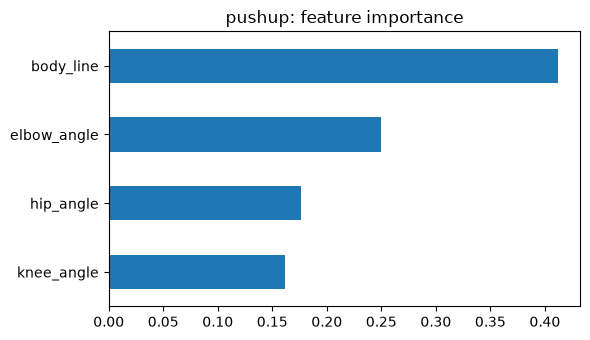

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

In [18]:
train("pushup")


=== squat (leave-one-subject-out) ===
frame-level accuracy: 0.60
video-level accuracy: 0.66

              precision    recall  f1-score   support

         bad       0.63      0.76      0.69        25
        good       0.70      0.56      0.62        25

    accuracy                           0.66        50
   macro avg       0.67      0.66      0.66        50
weighted avg       0.67      0.66      0.66        50

confusion matrix (rows = true bad/good, cols = predicted bad/good):
[[19  6]
 [11 14]]

misclassified videos (go watch these): ['subject_002_squat_good_front.mp4', 'subject_003_squat_bad_front.mp4', 'subject_003_squat_good_front.mp4', 'subject_004_squat_good_front.mp4', 'subject_005_squat_good_front.mp4', 'subject_006_squat_bad_front.mp4', 'subject_007_squat_good_front.mp4', 'subject_008_squat_good_front.mp4', 'subject_011_squat_bad_front.mp4', 'subject_012_squat_bad_front.mp4', 'subject_014_squat_bad_front.mp4', 'subject_015_squat_good_front.mp4', 'subject_016_squat_bad_f

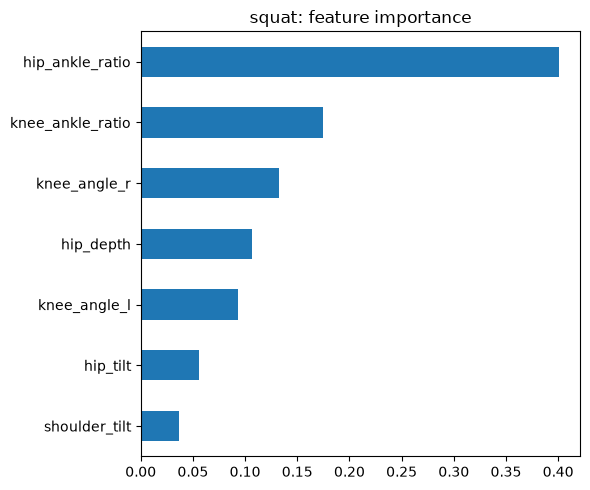

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 T

In [19]:
train("squat")

**Reading the results**
- Video-level accuracy is noisy with ~52 videos (one wrong video moves it ~2%), so treat small differences as noise.
- Go watch the misclassified videos. Usually it's a bad label, bad tracking, or a subtle mistake the features can't see.
- If squat is much worse than push-up, it's probably depth: front view can't see it well.
- Feature importance should match the EDA separation table. If it doesn't, find out why.

## 6b. Other models: video-level and sliding window

The frame-by-frame model judges one posture at a time, but form shows up over a movement. Two alternatives:

- **Video-level:** one row per video (mean / std / min / max of each feature), 48-50 rows per exercise. Heavily regularised models, because rows are scarce.
- **Sliding window:** summarise ~2 s windows (`WINDOW` sampled frames) the same way, classify each window, then vote per video. This is the version that maps to a live app (rolling window instead of a single frame).

Differences of a few percent are noise with ~50 videos (one video is 2%). Report which models you tried, not just the best one.

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


def video_table(exercise):
    df = DATA[exercise]
    base = [c for c in df.columns if c not in TRAIN_DROP]
    agg = df.groupby("video")[base].agg(["mean", "std", "min", "max"])
    agg.columns = [f"{a}_{b}" for a, b in agg.columns]
    meta = df.groupby("video").agg(label=("label", "first"), subject=("subject", "first"))
    return agg.join(meta)


def train_video_level(exercise):
    V = video_table(exercise)
    X, y, groups = V.drop(columns=["label", "subject"]), V["label"], V["subject"]
    models = {
        "logreg": make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=1000)),
        "forest": RandomForestClassifier(n_estimators=300, max_depth=3,
                                         min_samples_leaf=3, random_state=42),
    }
    for name, m in models.items():
        pred = cross_val_predict(m, X, y, groups=groups, cv=LeaveOneGroupOut())
        print(f"\n{exercise} / {name}: video accuracy {accuracy_score(y, pred):.2f}")
        print(confusion_matrix(y, pred))


train_video_level("pushup")
train_video_level("squat")


pushup / logreg: video accuracy 0.75
[[17  7]
 [ 5 19]]

pushup / forest: video accuracy 0.65
[[16  8]
 [ 9 15]]

squat / logreg: video accuracy 0.64
[[16  9]
 [ 9 16]]

squat / forest: video accuracy 0.70
[[18  7]
 [ 8 17]]


In [21]:
WINDOW = 20   # sampled frames per window (~2 s at 30 fps with EVERY_N = 3)
STEP = 5      # slide by 5 sampled frames


def window_features(df, window=WINDOW, step=STEP):
    base = [c for c in df.columns if c not in TRAIN_DROP]
    rows = []
    for video, g in df.groupby("video"):
        g = g.sort_values("frame")
        for s in range(0, max(len(g) - window, 0) + 1, step):
            w = g.iloc[s:s + window]
            if len(w) < window // 2:
                continue
            r = {"video": video, "label": g.label.iloc[0], "subject": g.subject.iloc[0]}
            for c in base:
                v = w[c].to_numpy()
                r[f"{c}_min"], r[f"{c}_max"] = v.min(), v.max()
                r[f"{c}_mean"], r[f"{c}_std"] = v.mean(), v.std()
                r[f"{c}_range"] = v.max() - v.min()
            rows.append(r)
    return pd.DataFrame(rows)


def train_windows(exercise):
    W = window_features(DATA[exercise])
    X, y, groups = W.drop(columns=["video", "label", "subject"]), W["label"], W["subject"]
    pred = cross_val_predict(make_model(), X, y, groups=groups, cv=LeaveOneGroupOut())

    vid = W[["video", "label"]].assign(pred=pred).groupby("video").agg(
        label=("label", "first"), pred=("pred", "mean"))
    vid["pred"] = (vid["pred"] > 0.5).astype(int)

    print(f"\n=== {exercise} (windows, leave-one-subject-out) ===")
    print(f"windows: {len(W)} | window-level accuracy: {accuracy_score(y, pred):.2f}")
    print(f"video-level accuracy: {accuracy_score(vid.label, vid.pred):.2f}\n")
    print(classification_report(vid.label, vid.pred, target_names=["bad", "good"]))
    print(confusion_matrix(vid.label, vid.pred))
    print("misclassified:", vid[vid.label != vid.pred].index.tolist() or "none")


train_windows("pushup")
train_windows("squat")


=== pushup (windows, leave-one-subject-out) ===
windows: 808 | window-level accuracy: 0.76
video-level accuracy: 0.79

              precision    recall  f1-score   support

         bad       0.79      0.79      0.79        24
        good       0.79      0.79      0.79        24

    accuracy                           0.79        48
   macro avg       0.79      0.79      0.79        48
weighted avg       0.79      0.79      0.79        48

[[19  5]
 [ 5 19]]
misclassified: ['subject_004_push_up_good_side.mp4', 'subject_005_push_up_good_side.mp4', 'subject_008_push_up_bad_side.mp4', 'subject_013_push_up_bad_side.mp4', 'subject_016_push_up_good_side.mp4', 'subject_017_push_up_bad_side.mp4', 'subject_019_push_up_good_side.mp4', 'subject_020_push_up_good_side.mp4', 'subject_021_push_up_bad_side.mp4', 'subject_024_push_up_bad_side.mp4']

=== squat (windows, leave-one-subject-out) ===
windows: 1085 | window-level accuracy: 0.67
video-level accuracy: 0.74

              precision    recall

## 7. Cross-dataset tests (push-up)

Train on one source and test on the other. Neither side is ever used for fitting its own test, so these are the cleanest generalisation numbers you have.

- **original → extra:** does a model trained on the downloaded dataset work on your extra clips?
- **extra → original:** the reverse. If both directions work, the model really generalises.

Each test lists the **wrongly classified clips with their person id**. If the mistakes cluster on one person, that's a source or setup issue, not a form issue. `good_frac` is the share of frames predicted good (0.5 = coin flip).

In [22]:
def cross_test(train_df, test_df, title):
    cols = [c for c in train_df.columns if c not in TRAIN_DROP]
    m = make_model().fit(train_df[cols], train_df["label"])
    t = test_df.copy()
    t["pred"] = m.predict(t[cols])
    v = t.groupby("video").agg(label=("label", "first"), subject=("subject", "first"),
                               frames=("frame", "size"), good_frac=("pred", "mean")).round(2)
    v["verdict"] = (v.good_frac > 0.5).astype(int)
    print(f"=== {title} ===")
    print(f"video-level accuracy: {accuracy_score(v.label, v.verdict):.2f}  ({len(v)} videos)")
    print("rows = true bad/good, cols = predicted bad/good")
    print(confusion_matrix(v.label, v.verdict, labels=[0, 1]))
    wrong = v[v.verdict != v.label].sort_values("good_frac")
    print(f"\nwrong clips ({len(wrong)}):")
    display(wrong)
    return v


if EXTRA is None:
    print("no extra clips loaded (section 4b), skipping")
else:
    EXTRA_CLEAN = EXTRA.drop(columns=["pred"], errors="ignore")
    v_fwd = cross_test(DATA["pushup"], EXTRA_CLEAN, "train = original dataset, test = extra clips")

=== train = original dataset, test = extra clips ===
video-level accuracy: 0.81  (99 videos)
rows = true bad/good, cols = predicted bad/good
[[42  7]
 [12 38]]

wrong clips (19):


,label,subject,frames,good_frac,verdict
video,,,,,
x_Copy of push up 78.mp4,1,1045,19,0.32,0
x_Copy of push up 1.mp4,1,1000,20,0.35,0
x_Copy of push up 116.mp4,1,1007,25,0.36,0
x_Copy of push up 100.mp4,1,1001,41,0.39,0
x_Copy of push up 79.mp4,1,1046,15,0.40,0
x_Copy of push up 115.mp4,1,1006,45,0.40,0
x_Copy of push up 186.mp4,1,1034,22,0.45,0
x_Copy of push up 134.mp4,1,1013,25,0.48,0
x_Copy of push up 187.mp4,1,1035,23,0.48,0


In [23]:
if EXTRA is not None:
    v_rev = cross_test(EXTRA_CLEAN, DATA["pushup"], "train = extra clips, test = original dataset")

=== train = extra clips, test = original dataset ===
video-level accuracy: 0.69  (48 videos)
rows = true bad/good, cols = predicted bad/good
[[14 10]
 [ 5 19]]

wrong clips (15):


,label,subject,frames,good_frac,verdict
video,,,,,
subject_011_push_up_good_side.mp4,1,11,45,0.31,0
subject_005_push_up_good_side.mp4,1,5,91,0.33,0
subject_021_push_up_good_side.mp4,1,21,77,0.40,0
subject_004_push_up_good_side.mp4,1,4,102,0.43,0
subject_023_push_up_good_side.mp4,1,23,94,0.43,0
subject_011_push_up_bad_side.mp4,0,11,85,0.53,1
subject_004_push_up_bad_side.mp4,0,4,137,0.54,1
subject_014_push_up_bad_side.mp4,0,14,84,0.56,1
subject_020_push_up_bad_side.mp4,0,20,84,0.56,1


## 8. Squat: does the tracking-jump filter hurt?

In the squat QC table (5.2), many videos lose a large share of frames to the **jump filter** (e.g. 93 of 152 sampled frames in one video). A squat moves the hips a lot and changes torso size toward the camera, so the filter may be deleting the deep frames that carry the depth information.

This re-extracts squat with the filter off and with a looser threshold and compares leave-one-subject-out accuracy against the current data. It does **not** touch your cached CSVs. Takes a few minutes per setting.

If a setting clearly helps, set it in section 1 (`USE_JUMP_FILTER` / `MAX_JUMP`), set `FORCE_EXTRACT = True` once, and re-run from section 4. Check the skeleton overlays too: with the filter off, make sure the tracker isn't jumping to background people.

In [24]:
def loso_video_acc(df):
    X, y, g = df.drop(columns=TRAIN_DROP), df["label"], df["subject"]
    pred = cross_val_predict(make_model(), X, y, groups=g, cv=LeaveOneGroupOut())
    vid = df[["video", "label"]].assign(pred=pred).groupby("video").agg(
        label=("label", "first"), pred=("pred", "mean"))
    vid["pred"] = (vid["pred"] > 0.5).astype(int)
    return (round(accuracy_score(y, pred), 2), round(accuracy_score(vid.label, vid.pred), 2),
            confusion_matrix(vid.label, vid.pred))


print(f"current setting {USE_JUMP_FILTER['squat']}/{MAX_JUMP['squat']}: "
      f"{len(DATA['squat'])} rows -> (frame acc, video acc, matrix) =", loso_video_acc(DATA["squat"]))

SQUAT_VARIANTS = {}
for name, kw in {"filter off": dict(jump_filter=False),
                 "looser (0.30)": dict(max_jump=0.30)}.items():
    SQUAT_VARIANTS[name], _ = build_dataset("squat", **kw)
    print(f"\n{name}: {len(SQUAT_VARIANTS[name])} rows -> (frame acc, video acc, matrix) =",
          loso_video_acc(SQUAT_VARIANTS[name]))

current setting True/0.15: 6281 rows -> (frame acc, video acc, matrix) = (0.6, 0.66, array([[19,  6],
       [11, 14]]))


squat:   0%|          | 0/50 [00:00<?, ?it/s]


filter off: 7143 rows -> (frame acc, video acc, matrix) = (0.61, 0.66, array([[20,  5],
       [12, 13]]))


squat:   0%|          | 0/50 [00:00<?, ?it/s]


looser (0.30): 6359 rows -> (frame acc, video acc, matrix) = (0.6, 0.68, array([[20,  5],
       [11, 14]]))


## 9. Final models for the app

Train on **all** available data and save to `outputs/<exercise>_model.pkl` (this overwrites the models saved in section 6). Push-up uses the original dataset **plus** the extra clips; squat uses the original dataset.

Don't evaluate these: they have seen every video. The honest numbers are the leave-one-subject-out and cross-dataset results above. Run this cell last, then use `live_demo.py`.

In [25]:
def train_final(exercise, use_extra=True):
    df = DATA[exercise]
    if exercise == "pushup" and use_extra and EXTRA is not None:
        df = pd.concat([df, EXTRA.drop(columns=["pred"], errors="ignore")], ignore_index=True)
    cols = [c for c in df.columns if c not in TRAIN_DROP]
    model = make_model().fit(df[cols], df["label"])
    joblib.dump((model, cols), OUT_DIR / f"{exercise}_model.pkl")
    print(f"{exercise}: trained on {df.video.nunique()} videos / {len(df)} frames "
          f"-> {OUT_DIR / (exercise + '_model.pkl')}")


train_final("pushup")
train_final("squat")

pushup: trained on 147 videos / 8418 frames -> outputs\pushup_model.pkl
squat: trained on 50 videos / 6281 frames -> outputs\squat_model.pkl


## 9b. Window models for the live app

`live_demo_window.py` classifies a rolling window of the last `WINDOW` samples (~2 s) instead of single frames, which is what scored best in section 6b. This trains the same window model on all data (push-up: original + extra clips) and saves it as `outputs/<exercise>_window_model.pkl` together with the window settings. Don't evaluate it: it has seen every video.

In [26]:
def train_final_windows(exercise, use_extra=True):
    df = DATA[exercise]
    if exercise == "pushup" and use_extra and EXTRA is not None:
        df = pd.concat([df, EXTRA.drop(columns=["pred"], errors="ignore")], ignore_index=True)
    W = window_features(df)
    cols = [c for c in W.columns if c not in ("video", "label", "subject")]
    model = make_model().fit(W[cols], W["label"])
    joblib.dump({"model": model, "cols": cols, "window": WINDOW, "every_n": EVERY_N},
                OUT_DIR / f"{exercise}_window_model.pkl")
    print(f"{exercise}: {df.video.nunique()} videos -> {len(W)} windows "
          f"-> {OUT_DIR / (exercise + '_window_model.pkl')}")


train_final_windows("pushup")
train_final_windows("squat")

pushup: 147 videos -> 1200 windows -> outputs\pushup_window_model.pkl
squat: 50 videos -> 1085 windows -> outputs\squat_window_model.pkl


## 10. Predict one video

Quick way to try the saved model on a single video. Output is the verdict and how many frames looked good.

In [27]:
def predict_video(path, exercise):
    model, cols = joblib.load(OUT_DIR / f"{exercise}_model.pkl")
    rows, st = extract_video(Path(path), exercise)
    if not rows:
        print("no usable frames:", st)
        return
    pred = model.predict(pd.DataFrame(rows)[cols])
    good = pred.mean()
    print(f"{Path(path).name}: {'GOOD' if good > 0.5 else 'BAD'}  "
          f"({good:.0%} of {len(pred)} frames look good)")


# example:
# predict_video("my_pushup.mp4", "pushup")

---
**Next:** run `python live_demo.py pushup` (or `squat`) for the webcam version. It loads the models saved in `outputs/` and uses the same `features.py`. Hook your timer to its `GOOD` / `BAD` status.

For the report: use the leave-one-subject-out and cross-dataset numbers (sections 6, 6b, 7). Mention every model you tried, and that differences of a few percent are within noise at this sample size.